# Day 1 – Autoencoder anomaly detection on construction-worker IMU data

**Group 3 · AI Methods I · VTT-ConIoT dataset (CC BY 4.0, Zenodo 4683703)**

**Use (one of the five):** anomaly detection. The autoencoder learns what routine site movement looks like
(walking, winding walk, pushing a cart) and flags windows that do not look like it.

**What this does and does not show.** It detects *unusual movement compared with routine movement*.
It is **not** a fatigue, stress or safety score, and the data has no such labels.

| | Tasks |
|---|---|
| Normal (train on these only) | 13 walk straight, 14 walk winding, 15 pushing cart |
| Anomalous (test only) | 7 jumping down, 8 laying back, 11 crouch floor, 12 kneel floor |
| Not used here | all other tasks |

Participants never overlap between splits: train 1-9, validation 10-11, test 12-13.
Threshold = 95th percentile of the reconstruction error on **normal validation windows**.

In [1]:
import os, ctypes
# Windows workaround: load the system C++ runtime before PyTorch.
if os.name == "nt":
    ctypes.WinDLL(os.path.join(os.environ["SystemRoot"], "System32", "msvcp140.dll"))

import copy, json, random, re, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score

HERE = Path.cwd()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "data").exists())
DATA_DIR = ROOT / "data"
REPORT_DIR = ROOT / "reports" / "anomaly"
MODEL_DIR = ROOT / "models" / "anomaly"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

WINDOW, STRIDE, BATCH_SIZE, EPOCHS, PATIENCE, SEED = 200, 100, 128, 30, 5, 42
TRAIN_USERS, VAL_USERS, TEST_USERS = list(range(1, 10)), [10, 11], [12, 13]
NORMAL, ANOMALOUS = [13, 14, 15], [7, 8, 11, 12]
FEATURES = [f"{loc}_{m}" for loc in ["trousers", "back", "hand"]
            for m in ["Ax_g", "Ay_g", "Az_g", "Gx_dps", "Gy_dps", "Gz_dps"]]
C = len(FEATURES)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Root:", ROOT, "| device:", device, "| torch", torch.__version__)

Root: d:\Work\IAAC\Hackaton_Group3_AIMethods | device: cpu | torch 2.15.0+cpu


## 1. Load the recordings

In [2]:
def load_recordings(tasks):
    records = []
    for path in sorted(DATA_DIR.rglob("activity_*_user_*_combined.csv")):
        m = re.fullmatch(r"activity_(\d+)_user_(\d+)_combined.csv", path.name)
        if not m:
            continue
        activity, user = map(int, m.groups())
        if activity not in tasks:
            continue
        df = pd.read_csv(path)
        values = df[FEATURES].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float32)
        records.append((user, activity, path.name, values))
    return records

records = load_recordings(NORMAL + ANOMALOUS)
print("Recordings loaded:", len(records))
pd.DataFrame([(u, a, len(v)) for u, a, _, v in records],
             columns=["user", "task", "rows"]).groupby("task").agg(
    recordings=("user", "count"), mean_rows=("rows", "mean"))

Recordings loaded: 90


,recordings,mean_rows
task,,
7,13,5999.076923
8,13,5999.153846
11,12,5999.250000
12,13,5999.230769
13,13,5999.076923
14,13,5999.076923
15,13,5999.076923


## 2. Windows and standardisation
Windows are 200 samples (2 s at 100 Hz) x 18 channels. Training windows overlap by 50 %,
validation and test windows do not overlap. Windows containing missing values are skipped.
The mean and standard deviation come from **normal training windows only**.

In [3]:
def raw_windows(users, tasks, stride):
    X, meta = [], []
    for user, activity, _, values in records:
        if user not in users or activity not in tasks:
            continue
        for s in range(0, len(values) - WINDOW + 1, stride):
            w = values[s:s + WINDOW]
            if np.isfinite(w).all():
                X.append(w)
                meta.append((user, activity))
    return np.stack(X).astype(np.float32), np.array(meta)

train_raw, _ = raw_windows(TRAIN_USERS, NORMAL, STRIDE)
val_raw, val_meta = raw_windows(VAL_USERS, NORMAL, WINDOW)
test_raw, test_meta = raw_windows(TEST_USERS, NORMAL + ANOMALOUS, WINDOW)

rows = train_raw.reshape(-1, C)
mean = rows.mean(axis=0)
scale = np.maximum(rows.std(axis=0), 1e-6)
std = lambda x: ((x - mean) / scale).astype(np.float32)
train_x, val_x, test_x = std(train_raw), std(val_raw), std(test_raw)

test_label = np.isin(test_meta[:, 1], ANOMALOUS).astype(int)   # 1 = anomalous
print(f"train (normal): {len(train_x)} | validation (normal): {len(val_x)}")
print(f"test: {len(test_x)} windows = {(test_label == 0).sum()} normal + {(test_label == 1).sum()} anomalous")

train (normal): 1566 | validation (normal): 175
test: 406 windows = 174 normal + 232 anomalous


## 3. Three setups
Same data, same training loop. Only the architecture changes.

| Setup | Idea |
|---|---|
| **A. Dense, latent 32** | fully connected encoder and decoder (the Monday model) |
| **B. Conv1d, latent 32** | 1D convolutions along time |
| **C. Conv1d, latent 16** | same, smaller bottleneck |

In [4]:
class Dense(nn.Module):
    def __init__(self, latent=32):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(WINDOW * C, 256), nn.ReLU(),
                                 nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, latent))
        self.dec = nn.Sequential(nn.Linear(latent, 64), nn.ReLU(), nn.Linear(64, 256), nn.ReLU(),
                                 nn.Linear(256, WINDOW * C), nn.Unflatten(1, (WINDOW, C)))
    def encode(self, x): return self.enc(x)
    def decode(self, z): return self.dec(z)
    def forward(self, x): return self.decode(self.encode(x))

class Conv(nn.Module):
    def __init__(self, latent=32):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv1d(C, 32, 5, 2, 2), nn.ReLU(),
            nn.Conv1d(32, 64, 5, 2, 2), nn.ReLU(),
            nn.Conv1d(64, 64, 5, 2, 2), nn.ReLU(),
            nn.Flatten(), nn.Linear(64 * 25, latent))
        self.dec = nn.Sequential(
            nn.Linear(latent, 64 * 25), nn.ReLU(), nn.Unflatten(1, (64, 25)),
            nn.ConvTranspose1d(64, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose1d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose1d(32, C, 4, 2, 1))
    def encode(self, x): return self.enc(x.transpose(1, 2))      # (batch, time, ch) -> (batch, ch, time)
    def decode(self, z): return self.dec(z).transpose(1, 2)
    def forward(self, x): return self.decode(self.encode(x))

SETUPS = {
    "A Dense, latent 32":  lambda: Dense(32),
    "B Conv1d, latent 32": lambda: Conv(32),
    "C Conv1d, latent 16": lambda: Conv(16),
}

In [5]:
def make_loader(a, shuffle=False):
    return DataLoader(TensorDataset(torch.from_numpy(a)), batch_size=BATCH_SIZE, shuffle=shuffle)

def window_errors(model, x):
    # Mean squared reconstruction error per window.
    model.eval()
    out = []
    with torch.no_grad():
        for (b,) in make_loader(x):
            b = b.to(device)
            out.append((model(b) - b).square().mean(dim=(1, 2)).cpu().numpy())
    return np.concatenate(out)

def train(name, build):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    model = build().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    n_params = sum(p.numel() for p in model.parameters())
    history, best, best_state, stale = [], float("inf"), None, 0
    t0 = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train(); total = 0.0
        for (b,) in make_loader(train_x, shuffle=True):
            b = b.to(device)
            opt.zero_grad(set_to_none=True)
            loss = (model(b) - b).square().mean()
            loss.backward(); opt.step()
            total += loss.item() * len(b)
        tr, va = total / len(train_x), float(window_errors(model, val_x).mean())
        history.append((epoch, tr, va))
        print(f"{name} | epoch {epoch:02d} | train {tr:.4f} | val {va:.4f}")
        if va < best:
            best, best_state, stale = va, copy.deepcopy(model.state_dict()), 0
        else:
            stale += 1
            if stale >= PATIENCE:
                print("early stopping"); break
    seconds = time.perf_counter() - t0
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history, columns=["epoch", "train", "val"]), n_params, seconds

trained = {}
for name, build in SETUPS.items():
    trained[name] = train(name, build)

A Dense, latent 32 | epoch 01 | train 0.9667 | val 1.2481
A Dense, latent 32 | epoch 02 | train 0.7887 | val 1.1051
A Dense, latent 32 | epoch 03 | train 0.6682 | val 0.9892
A Dense, latent 32 | epoch 04 | train 0.5899 | val 0.9333
A Dense, latent 32 | epoch 05 | train 0.5450 | val 0.9011
A Dense, latent 32 | epoch 06 | train 0.5163 | val 0.8854
A Dense, latent 32 | epoch 07 | train 0.4911 | val 0.8719
A Dense, latent 32 | epoch 08 | train 0.4702 | val 0.8624
A Dense, latent 32 | epoch 09 | train 0.4530 | val 0.8511
A Dense, latent 32 | epoch 10 | train 0.4377 | val 0.8393
A Dense, latent 32 | epoch 11 | train 0.4245 | val 0.8327
A Dense, latent 32 | epoch 12 | train 0.4132 | val 0.8235
A Dense, latent 32 | epoch 13 | train 0.4027 | val 0.8155
A Dense, latent 32 | epoch 14 | train 0.3925 | val 0.8060
A Dense, latent 32 | epoch 15 | train 0.3843 | val 0.8023
A Dense, latent 32 | epoch 16 | train 0.3781 | val 0.7954
A Dense, latent 32 | epoch 17 | train 0.3711 | val 0.7897
A Dense, laten

## 4. Results
- **Model selection:** choose among the three neural networks by the lowest mean MSE on normal validation windows. Test metrics are reserved for final evaluation and comparison.
- **Test ROC AUC:** how well each score separates the selected anomalous tasks from normal tasks for held-out workers (0.5 = random, 1.0 = perfect).
- **Precision / recall:** final test metrics using the threshold set to the 95th percentile of normal validation error.
- **Baseline:** signal energy mean(x^2) of the standardized window, included for test comparison and excluded from neural-network model selection.


In [6]:
rows_out, scores, thresholds = [], {}, {}
for name, (model, hist, n_params, seconds) in trained.items():
    val_err = window_errors(model, val_x)
    test_err = window_errors(model, test_x)
    thr = float(np.percentile(val_err, 95))
    pred = (test_err > thr).astype(int)
    scores[name], thresholds[name] = test_err, thr
    rows_out.append({
        "Setup": name, "Parameters": n_params, "Training time (s)": round(seconds, 1),
        "Epochs run": len(hist), "Val MSE (normal)": round(float(val_err.mean()), 4),
        "Test MSE (all)": round(float(test_err.mean()), 4),
        "ROC AUC": round(roc_auc_score(test_label, test_err), 3),
        "Precision": round(precision_score(test_label, pred, zero_division=0), 3),
        "Recall": round(recall_score(test_label, pred, zero_division=0), 3),
        "Threshold": round(thr, 4)})

base_val_err = (val_x ** 2).mean(axis=(1, 2))
base_err = (test_x ** 2).mean(axis=(1, 2))
rows_out.append({"Setup": "Baseline: signal energy", "Val MSE (normal)": round(float(base_val_err.mean()), 4),
                "Test MSE (all)": round(float(base_err.mean()), 4),
                "ROC AUC": round(roc_auc_score(test_label, base_err), 3)})
results = pd.DataFrame(rows_out)
results.to_csv(REPORT_DIR / "setups_table.csv", index=False)
results


,Setup,Parameters,Training time (s),Epochs run,Val MSE (normal),Test MSE (all),ROC AUC,Precision,Recall,Threshold
0,"A Dense, latent 32",1884336.0,2.5,30.0,0.7674,1.1797,0.820,0.923,0.310,1.5941
1,"B Conv1d, latent 32",164786.0,4.9,30.0,0.8225,1.4103,0.844,0.926,0.323,1.7134
2,"C Conv1d, latent 16",113570.0,5.2,30.0,0.8828,1.4622,0.846,0.929,0.336,1.7366
3,Baseline: signal energy,NaN,NaN,NaN,1.4384,1.7683,0.688,NaN,NaN,NaN


## 5. Proving figures

Neural network selected by normal validation MSE only: A Dense, latent 32 (0.7674)


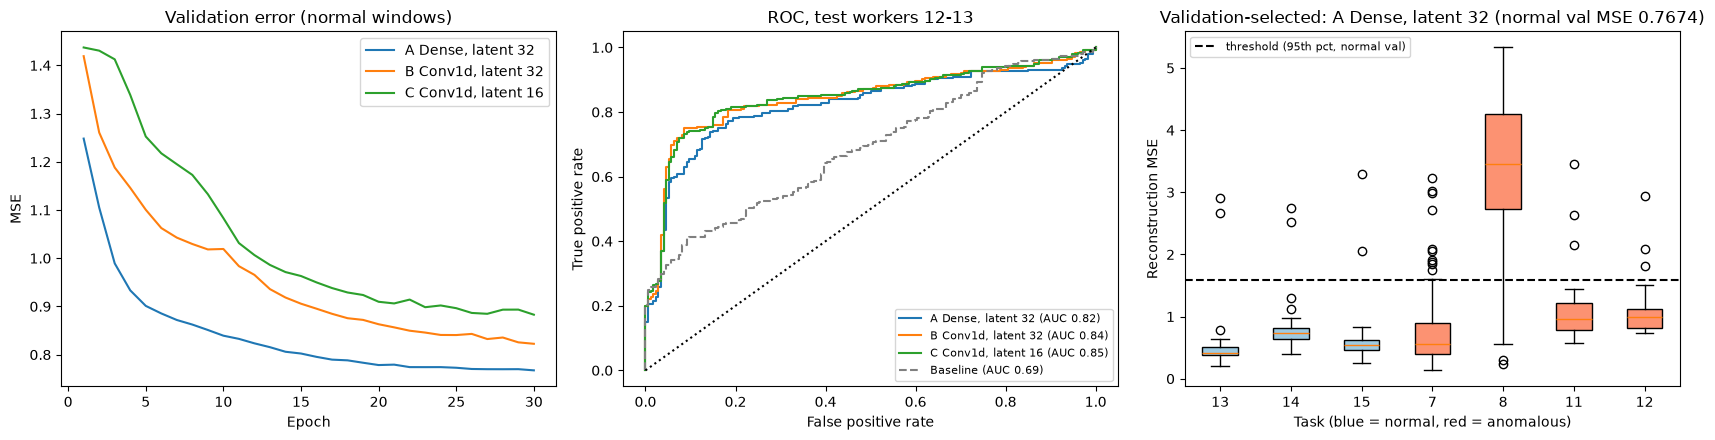

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

for name, (_, hist, _, _) in trained.items():
    ax[0].plot(hist.epoch, hist.val, label=name)
ax[0].set(title="Validation error (normal windows)", xlabel="Epoch", ylabel="MSE"); ax[0].legend()

for name, e in scores.items():
    fpr, tpr, _ = roc_curve(test_label, e)
    ax[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(test_label, e):.2f})")
fpr, tpr, _ = roc_curve(test_label, base_err)
ax[1].plot(fpr, tpr, "--", color="grey", label=f"Baseline (AUC {roc_auc_score(test_label, base_err):.2f})")
ax[1].plot([0, 1], [0, 1], ":", color="black")
ax[1].set(title="ROC, test workers 12-13", xlabel="False positive rate", ylabel="True positive rate"); ax[1].legend(fontsize=8)

best_name = min(SETUPS, key=lambda name: float(window_errors(trained[name][0], val_x).mean()))
best_val_mse = float(window_errors(trained[best_name][0], val_x).mean())
tasks = NORMAL + ANOMALOUS
data = [scores[best_name][test_meta[:, 1] == t] for t in tasks]
bp = ax[2].boxplot(data, tick_labels=[str(t) for t in tasks], patch_artist=True)
for patch, t in zip(bp["boxes"], tasks):
    patch.set_facecolor("#9ecae1" if t in NORMAL else "#fc9272")
ax[2].axhline(thresholds[best_name], color="black", linestyle="--", label="threshold (95th pct, normal val)")
ax[2].set(title=f"Validation-selected: {best_name} (normal val MSE {best_val_mse:.4f})", xlabel="Task (blue = normal, red = anomalous)", ylabel="Reconstruction MSE")
ax[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig(REPORT_DIR / "anomaly_figure.png", dpi=160)
print(f"Neural network selected by normal validation MSE only: {best_name} ({best_val_mse:.4f})")


## 6. Interpretation (fill in after running)

- Select the neural network with the lowest mean reconstruction MSE on normal validation windows; report test metrics only as final held-out evaluation and comparison.
- Describe which selected tasks 7, 8, 11, and 12 have higher or lower reconstruction error, without treating this as a validated worker-strain label.
- Limits: only workers 12 and 13 are in the test set, the tasks are short scripted recordings, and anomalous means different from selected normal tasks 13, 14, and 15. This does not indicate fatigue, danger, stress, or a validated worker-strain label.


## 7. Save the best model for the model server

In [8]:
best_model = trained[best_name][0].cpu().eval()
tag = best_name.split()[0]

class WithEmbedding(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        z = self.m.encode(x)
        return z, self.m.decode(z)

example = torch.zeros(1, WINDOW, C, dtype=torch.float32)
onnx_path = MODEL_DIR / "model.onnx"
torch.onnx.export(
    WithEmbedding(best_model).eval(), (example,), str(onnx_path),
    input_names=["sensor_window"], output_names=["embedding", "reconstruction"],
    dynamic_shapes={"x": {0: torch.export.Dim("batch")}}, external_data=False)

np.savez(MODEL_DIR / "scaler.npz", mean=mean, scale=scale)
config = {"model": best_name, "window": WINDOW, "sampling_rate_hz": 100, "features": FEATURES,
          "normal_tasks": NORMAL, "anomalous_tasks": ANOMALOUS,
          "threshold_mse": thresholds[best_name], "threshold_rule": "95th percentile of normal validation error",
          "train_users": TRAIN_USERS, "validation_users": VAL_USERS, "test_users": TEST_USERS,
          "seed": SEED, "torch_version": str(torch.__version__)}
(MODEL_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

import onnxruntime as ort
sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
emb, rec = sess.run(["embedding", "reconstruction"], {"sensor_window": example.numpy()})
with torch.no_grad():
    z = best_model.encode(example)
print("ONNX matches PyTorch:", np.allclose(z.numpy(), emb, atol=1e-5),
      np.allclose(best_model.decode(z).detach().numpy(), rec, atol=1e-5), "| size", onnx_path.stat().st_size, "bytes")

[torch.onnx] Obtain model graph for `WithEmbedding([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `WithEmbedding([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX matches PyTorch: True True | size 7555647 bytes
